# Select metamodel goals in the AoI buffer ring

Workflow:

1. Auto-crop the **world-scale** hindcast catalogs and land polygons down to this
   AoI (once per case, into `hindcasts-aus/`), then load **AoI**, **land**, and
   all hindcast coordinates catalogs from it.
2. Build the **inland buffer ring**: `ring = (AoI - AoI.buffer(-d)) - land`.
3. Place **random spaced targets** inside the ring (open water), then number them **clockwise along the AoI boundary** (starting at the westernmost point).
4. For each target, snap to the **nearest node in every hindcast** catalog.
5. (Optional) Filter out goals that are too far from any hindcast node.
6. Compute **adaptive open-sea propagation sectors** from the nearest **AoI boundary** point.
7. (Optional) Manually override goal directions, re-plot, and then save JSON + GeoPackage.

**Direction convention** (`bluemath_tk.core.operations`): all stored `angles` are **nautical**
wave-from directions, **clockwise from North** (`0°` = N, `90°` = E). Each goal has
`[left, right]` with `left < right` (clockwise sector boundaries). If the sector crosses
North, `left` is negative (e.g. `[-10, 50]` = 350°->50° clockwise). This matches WHACS
and SnapWave forcing; LHS samples `dir` in that range and normalizes with `% 360`.

**Note**: `hindcasts-aus/` already exists (hand-clipped) and the `direction_overrides`
below were tuned against its exact goal numbering, so `prepare_case_hindcasts()` is a
no-op here. Only pass `overwrite=True` if you deliberately want to rebuild it -- goal
IDs/counts may shift and the overrides will need re-tuning.

In [1]:
import json

import geopandas as gpd
import pandas as pd
from bluemath_tk.waves.hywaves import sectors as hc
from utils.config import CASE_DIR, PATHS, resolve
from utils import viz as plot

## Parameters

In [2]:
buffer_distance_m = 5_000.0
min_spacing_m = 40_000.0

# Optional cap: drop goals if any hindcast snap distance exceeds this threshold.
# Set to None to disable filtering.
max_hindcast_distance_m = 500_000.0

sector_margin_deg = 5.0
random_seed = 42

geo_crs = "EPSG:4326"
work_crs = "EPSG:32702"  # TODO: UTM CRS for your region

# World-scale masters (not in git -- see the intro cell). Cropped once per case
# into hindcasts_dir by prepare_case_hindcasts(), below.
world_hindcasts_dir = CASE_DIR.parent / "QGIS/HyWorld/hindcasts"
world_land_path = CASE_DIR.parent / "QGIS/HyWorld/land/GSHHS_f_L1.shp"

hindcasts_dir = CASE_DIR.parent / "QGIS/HyWorld/hindcasts-NewSouthWales"
land_path = hindcasts_dir / "land.gpkg"

# Crop padding around the AoI bbox -- must cover max_hindcast_distance_m.
hindcasts_buffer_km = max(150.0, (max_hindcast_distance_m or 0) / 1_000 * 1.2)

from utils.config import SIMULATIONS

goals_out_path = resolve(SIMULATIONS["goals_file"])
goals_gpkg_path = goals_out_path.with_suffix(".gpkg")

print(f"AoI       : {resolve(PATHS['aoi_file'])}")
print(f"hindcasts : {hindcasts_dir}")
print(f"land      : {land_path}")
print(f"json      : {goals_out_path}")
print(f"gpkg      : {goals_gpkg_path}")
print(f"min dist  : {min_spacing_m} m")
print(f"max dist  : {max_hindcast_distance_m} m")

AoI       : /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/AoI_Polygons/NewSouthWales_AoI.shp
hindcasts : /home/tausiaj/GitHub-GeoOcean/HyGloW/QGIS/HyWorld/hindcasts-NewSouthWales
land      : /home/tausiaj/GitHub-GeoOcean/HyGloW/QGIS/HyWorld/hindcasts-NewSouthWales/land.gpkg
json      : /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/Goals/NewSouthWales_Goals.json
gpkg      : /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/Goals/NewSouthWales_Goals.gpkg
min dist  : 40000.0 m
max dist  : 500000.0 m


## Prepare per-case hindcasts (crop world masters to this AoI)

No-op here: `hindcasts_dir` already exists (`hindcasts-aus/`).

In [3]:
aoi = gpd.read_file(resolve(PATHS["aoi_file"])).to_crs(geo_crs)

hc.prepare_case_hindcasts(
    aoi,
    out_dir=hindcasts_dir,
    world_hindcasts_dir=world_hindcasts_dir,
    world_land_path=world_land_path,
    buffer_km=hindcasts_buffer_km,
)
print(f"hindcasts ready: {hindcasts_dir}")

hindcasts ready: /home/tausiaj/GitHub-GeoOcean/HyGloW/QGIS/HyWorld/hindcasts-NewSouthWales


## Load inputs

In [4]:
land = hc.load_land(land_path)
catalogs = hc.load_catalogs(hindcasts_dir)

print(f"AoI catalogs: {list(catalogs)}")
for name, gdf in catalogs.items():
    print(f"  {name:6s}: {len(gdf):4d} points")

AoI catalogs: ['codec', 'era5', 'whacs']
  codec :  292 points
  era5  : 1476 points
  whacs : 18203 points


## Buffer ring and random targets

In [5]:
ring_poly, ring_gdf = hc.build_ring(aoi, land, buffer_distance_m, work_crs)
targets = hc.random_targets_in_ring(
    ring_poly,
    land,
    min_spacing_m=min_spacing_m,
    work_crs=work_crs,
    random_seed=random_seed,
)
targets = hc.sort_targets_along_aoi(
    targets,
    aoi,
    work_crs=work_crs,
    clockwise=True,  # False = CCW; None = shapefile vertex order
    start_at="west",  # goal 1 starts at the westernmost AoI point
)

print(
    f"ring area : {gpd.GeoDataFrame(geometry=[ring_poly], crs=geo_crs).to_crs(work_crs).geometry.area.iloc[0] / 1e6:,.1f} km²"
)
print(f"targets   : {len(targets)}  (min spacing = {min_spacing_m / 1000:g} km)")
targets

ring area : 7,443.0 km²
targets   : 26  (min spacing = 40 km)


,geometry,goal_id
0,POINT (153.5466 -28.07764),1
1,POINT (154.04465 -27.88589),2
2,POINT (154.1626 -28.26031),3
3,POINT (154.27557 -28.84264),4
4,POINT (154.245 -29.1702),5
5,POINT (154.11268 -29.69856),6
6,POINT (154.10493 -30.27474),7
7,POINT (153.90604 -30.59844),8
8,POINT (153.68628 -31.13827),9
9,POINT (153.62464 -31.59463),10


## Build goals dict (target, angles, hindcast snaps)

`angles` = nautical clockwise `[left, right]` per goal (see notebook intro).

In [6]:
sectors = hc.AoIRingSectors.from_aoi(aoi, work_crs)
goals = hc.build_goals_dict(
    targets,
    catalogs,
    sectors,
    work_crs=work_crs,
    margin_deg=sector_margin_deg,
)

if max_hindcast_distance_m is not None:
    goals = {
        goal_id: goal
        for goal_id, goal in goals.items()
        if max(v["distance_m"] for v in goal["hindcast"].values())
        <= max_hindcast_distance_m
    }
    keep_ids = set(goals)
    targets = targets[targets["goal_id"].astype(str).isin(keep_ids)].copy()

boundary_snaps = hc.boundary_snaps(targets, sectors, work_crs=work_crs)

summary_df = pd.DataFrame(
    [
        {
            "goal": k,
            "target_lon": v["target"]["longitude"],
            "target_lat": v["target"]["latitude"],
            "angles": v["angles"],
            "max_dist_m": max(h["distance_m"] for h in v["hindcast"].values()),
            **{f"{h}_fid": v["hindcast"][h]["fid"] for h in v["hindcast"]},
            **{f"{h}_dist_m": v["hindcast"][h]["distance_m"] for h in v["hindcast"]},
        }
        for k, v in goals.items()
    ]
)

print(f"goals kept: {len(goals)}")
summary_df

goals kept: 26


,goal,target_lon,target_lat,angles,max_dist_m,codec_fid,era5_fid,whacs_fid,codec_dist_m,era5_dist_m,whacs_dist_m
0,1,153.546596,-28.077641,"[-172.1, 87.2]",13969.2,164,94,12947,13969.2,11354.2,2670.3
1,2,154.044650,-27.885886,"[-172.1, 87.2]",15530.9,165,95,14680,11970.4,15530.9,5629.7
2,3,154.162605,-28.260313,"[-62.4, 192.2]",38601.8,165,131,17892,38601.8,35868.0,5380.8
3,4,154.275571,-28.842639,"[-62.4, 192.2]",32262.1,159,13,14903,31202.0,32262.1,655.2
4,5,154.244995,-29.170202,"[-9.8, 183.2]",35118.6,159,12,14835,33761.2,35118.6,7417.9
5,6,154.112678,-29.698564,"[-28.2, 169.8]",42913.3,194,59,14715,42913.3,28338.8,5500.3
6,7,154.104927,-30.274739,"[-28.2, 169.8]",32103.7,194,1409,13614,32103.7,30984.6,9124.9
7,8,153.906040,-30.598436,"[5.8, 199.9]",74256.4,194,1409,37,74256.4,16289.8,598.5
8,9,153.686280,-31.138270,"[-12.7, 170.6]",70658.6,84,1448,12183,70658.6,27044.9,6569.7
9,10,153.624636,-31.594630,"[-6.0, 184.7]",80426.5,83,1397,12129,80426.5,18195.9,3450.9


## Optional direction overrides (edit and re-run)

You can manually adjust directions before plotting/saving.
Use nautical clockwise `[left, right]` with `left < right`.

Example:

```python
direction_overrides = {
    "1": [-20, 60],
    "3": [95, 180],
}
```

Using Esri World Imagery (ArcGIS):
- Free for public and non-commercial use
- Commercial use allowed under Esri terms of service
- Attribution required: 'Tiles © Esri — Sources: Esri, Earthstar Geographics, CNES/Airbus DS, USDA, USGS, AeroGRID, IGN, and the GIS User Community'
- Max zoom ~19


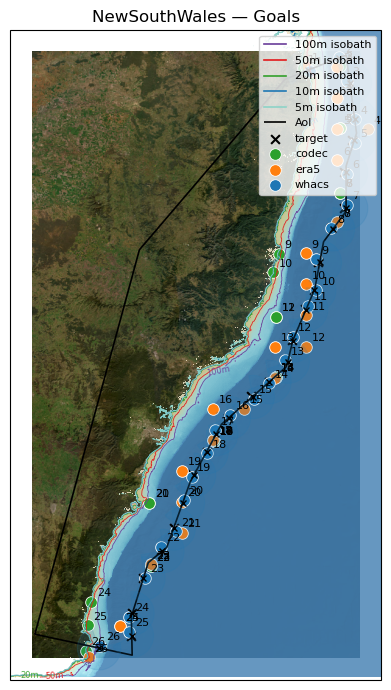

In [7]:
# Optionally edit this dictionary and rerun this cell.
direction_overrides: dict[str, list[float]] = {
    "1": [-130, 90],
    "2": [-130, 180],
    "3": [-35, 190],
    "4": [-35, 195],
    "5": [-25, 215],
    "6": [-5, 195],
    "7": [-20, 240],
    "8": [-0, 235],
    "9": [-10, 210],
    "10": [-5, 220],
    "11": [0, 220],
    "12": [-10, 210],
    "13": [-15, 250],
    "14": [-10, 250],
    "15": [-10, 250],
    "16": [-10, 250],
    "17": [0, 240],
    "18": [0, 240],
    "19": [0, 240],
    "20": [-5, 235],
    "21": [-5, 235],
    "22": [-5, 260],
    "23": [-5, 210],
    "24": [-5, 190],
    "25": [-15, 240],
    "26": [75, 340],
}

goals_final = json.loads(json.dumps(goals))
for goal_id, angles in direction_overrides.items():
    if goal_id not in goals_final:
        raise KeyError(f"Unknown goal_id in direction_overrides: {goal_id}")
    if len(angles) != 2 or angles[0] >= angles[1]:
        raise ValueError(
            f"{goal_id}: angles must be [left, right] with left < right, got {angles}"
        )
    goals_final[goal_id]["angles"] = [float(angles[0]), float(angles[1])]

fig, ax = plot.plot_base_map(
    title="Goals",
    show_topobathy=True,
    show_satellite=True,
)
plot.plot_sectors(targets, goals_final, boundary_snaps, ax)
targets.plot(ax=ax, color="black", markersize=40, marker="x", label="target")

plot.plot_points(
    hc.hindcast_snaps_gdf(goals_final),
    ax,
    color_col="catalog",
    label_col="goal_id",
    color_map=plot.HINDCAST_COLORS,
)

minx, miny, maxx, maxy = aoi.total_bounds
pad = 0.4
ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_aspect("equal", adjustable="box")

fig.tight_layout()

## Save goals JSON and QGIS GeoPackage

After saving, update the case JSON with your selected goals JSON path:

```json
"simulations": {
    "goals_file": "inputs/goals/<Case>_Goals.json"
}
```

In [8]:
goals_to_save = goals_final if "goals_final" in locals() else goals

goals_out_path.parent.mkdir(parents=True, exist_ok=True)

with goals_out_path.open("w", encoding="utf-8") as f:
    json.dump({"goals": goals_to_save}, f, indent=4)
    f.write("\n")

hc.save_goals_gpkg(
    goals_to_save, targets, boundary_snaps, goals_gpkg_path, ring=ring_gdf
)

print(f"Wrote {len(goals_to_save)} goal(s) to:")
print(f"  {goals_out_path}")
print(f"  {goals_gpkg_path}")
print(
    "\nGPKG layers: targets, boundary_snaps, sectors, links, buffer_ring, "
    "codec, era5, whacs"
)
print(json.dumps({"goals": goals_to_save}, indent=4))

Wrote 26 goal(s) to:
  /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/Goals/NewSouthWales_Goals.json
  /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/Goals/NewSouthWales_Goals.gpkg

GPKG layers: targets, boundary_snaps, sectors, links, buffer_ring, codec, era5, whacs
{
    "goals": {
        "1": {
            "target": {
                "longitude": 153.546596,
                "latitude": -28.077641
            },
… (777 more lines not shown)
